In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn nltk wordcloud

In [2]:
# Importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk

from nltk.corpus import stopwords

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


# 1. Data Loading and Inspection

In this section, we load the SMS Spam Collection dataset using Pandas. We inspect the dataset structure, display sample records, check the number of rows and columns, identify missing values, and examine duplicate records.

In [3]:
# Load the SMS Spam Collection dataset

df = pd.read_csv(
    "/content/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
# Display first five records

df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [5]:
# Check number of rows and columns

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)

Number of rows: 5572
Number of columns: 2
Dataset shape: (5572, 2)


In [6]:
# Display dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [7]:
# Check missing values in each column

print("Missing values:")
print(df.isnull().sum())

Missing values:
label      0
message    0
dtype: int64


In [8]:
# Count duplicate records

print("Total duplicate records:", df.duplicated().sum())

Total duplicate records: 403


In [9]:
# Remove duplicate records

df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (5169, 2)


In [10]:
# Display the cleaned dataset

df.head(10)

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


# 2. Spam and Ham Class Distribution Analysis

In this section, we analyze the distribution of spam and ham messages in the dataset. We calculate the total number and percentage of each category and visualize the class distribution using a bar chart. This analysis helps us understand whether the dataset is balanced or imbalanced.

In [11]:
# Count spam and ham messages

class_counts = df["label"].value_counts()

print("Message Distribution:")
print(class_counts)

Message Distribution:
label
ham     4516
spam     653
Name: count, dtype: int64


In [12]:
# Calculate percentage of each class

class_percentages = df["label"].value_counts(normalize=True) * 100

print("Class Distribution Percentage:")

print(class_percentages.round(2))

Class Distribution Percentage:
label
ham     87.37
spam    12.63
Name: proportion, dtype: float64


In [13]:
# Create a summary table

distribution = pd.DataFrame({
    "Message Type": class_counts.index,
    "Count": class_counts.values,
    "Percentage": class_percentages.values.round(2)
})

distribution

,Message Type,Count,Percentage
0,ham,4516,87.37
1,spam,653,12.63


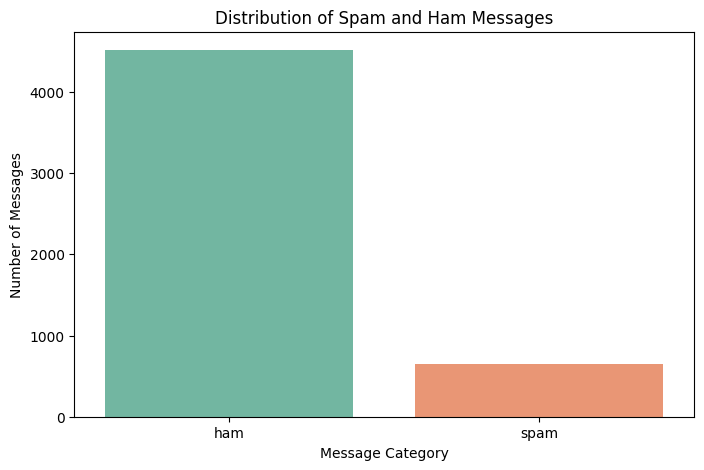

In [14]:
# Visualize spam and ham distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="label",
    hue="label",
    palette="Set2",
    legend=False
)

plt.title("Distribution of Spam and Ham Messages")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")

plt.show()

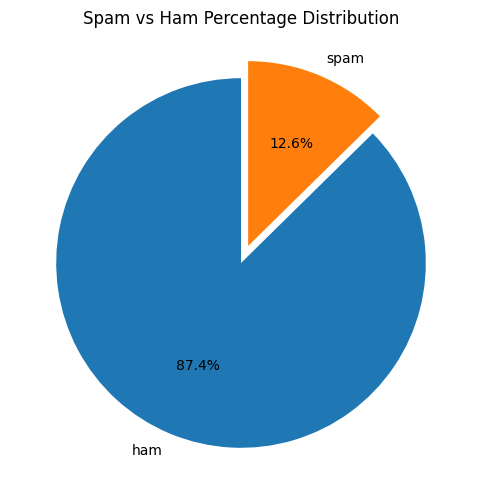

In [15]:
# Visualize percentage distribution

plt.figure(figsize=(6, 6))

plt.pie(
    class_counts,
    labels=class_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    explode=(0, 0.1)
)

plt.title("Spam vs Ham Percentage Distribution")

plt.show()

### Class Distribution Observation

The class distribution analysis shows that legitimate (ham) messages form the majority of the dataset, while spam messages represent a smaller proportion.

This indicates that the dataset is imbalanced. Therefore, accuracy alone may not be sufficient to evaluate the classification models. Precision, recall, and F1-score will also be considered during model evaluation.

# 3. Text Preprocessing Using NLP

Text preprocessing is an important step in Natural Language Processing (NLP). It involves cleaning and transforming raw text into a suitable format for machine learning.

In this project, we perform lowercase conversion, punctuation removal, extra space removal, and stopword removal to prepare SMS messages for classification.

In [16]:
# Download English stopwords from NLTK

import nltk

nltk.download('stopwords')

from nltk.corpus import stopwords

# Create a set of English stopwords

stop_words = set(stopwords.words('english'))

print("Stopwords downloaded successfully!")
print("Total stopwords:", len(stop_words))

Stopwords downloaded successfully!
Total stopwords: 198


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [17]:
# Convert all messages into lowercase

df["message_lower"] = df["message"].str.lower()

# Display original and lowercase messages

df[["message", "message_lower"]].head(10)

,message,message_lower
0,"Go until jurong point, crazy.. Available only ...","go until jurong point, crazy.. available only ..."
1,Ok lar... Joking wif u oni...,ok lar... joking wif u oni...
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,U dun say so early hor... U c already then say...,u dun say so early hor... u c already then say...
4,"Nah I don't think he goes to usf, he lives aro...","nah i don't think he goes to usf, he lives aro..."
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey there darling it's been 3 week's n...
6,Even my brother is not like to speak with me. ...,even my brother is not like to speak with me. ...
7,As per your request 'Melle Melle (Oru Minnamin...,as per your request 'melle melle (oru minnamin...
8,WINNER!! As a valued network customer you have...,winner!! as a valued network customer you have...
9,Had your mobile 11 months or more? U R entitle...,had your mobile 11 months or more? u r entitle...


In [18]:
# Remove punctuation and special characters

df["message_no_punctuation"] = df["message_lower"].apply(
    lambda text: re.sub(r'[^a-zA-Z\s]', '', text)
)

df[["message_lower", "message_no_punctuation"]].head(10)

,message_lower,message_no_punctuation
0,"go until jurong point, crazy.. available only ...",go until jurong point crazy available only in ...
1,ok lar... joking wif u oni...,ok lar joking wif u oni
2,free entry in 2 a wkly comp to win fa cup fina...,free entry in a wkly comp to win fa cup final...
3,u dun say so early hor... u c already then say...,u dun say so early hor u c already then say
4,"nah i don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...
5,freemsg hey there darling it's been 3 week's n...,freemsg hey there darling its been weeks now ...
6,even my brother is not like to speak with me. ...,even my brother is not like to speak with me t...
7,as per your request 'melle melle (oru minnamin...,as per your request melle melle oru minnaminun...
8,winner!! as a valued network customer you have...,winner as a valued network customer you have b...
9,had your mobile 11 months or more? u r entitle...,had your mobile months or more u r entitled t...


In [19]:
# Remove extra spaces from messages

df["message_no_extra_spaces"] = df["message_no_punctuation"].apply(
    lambda text: re.sub(r'\s+', ' ', text).strip()
)

df[["message_no_punctuation", "message_no_extra_spaces"]].head(10)

,message_no_punctuation,message_no_extra_spaces
0,go until jurong point crazy available only in ...,go until jurong point crazy available only in ...
1,ok lar joking wif u oni,ok lar joking wif u oni
2,free entry in a wkly comp to win fa cup final...,free entry in a wkly comp to win fa cup final ...
3,u dun say so early hor u c already then say,u dun say so early hor u c already then say
4,nah i dont think he goes to usf he lives aroun...,nah i dont think he goes to usf he lives aroun...
5,freemsg hey there darling its been weeks now ...,freemsg hey there darling its been weeks now a...
6,even my brother is not like to speak with me t...,even my brother is not like to speak with me t...
7,as per your request melle melle oru minnaminun...,as per your request melle melle oru minnaminun...
8,winner as a valued network customer you have b...,winner as a valued network customer you have b...
9,had your mobile months or more u r entitled t...,had your mobile months or more u r entitled to...


In [20]:
# Function to remove English stopwords

def remove_stopwords(text):

    words = text.split()

    filtered_words = [
        word for word in words
        if word not in stop_words
    ]

    return ' '.join(filtered_words)


# Apply stopword removal

df["cleaned_message"] = df["message_no_extra_spaces"].apply(
    remove_stopwords
)

# Display cleaned messages

df[["message", "cleaned_message"]].head(10)

,message,cleaned_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,"Nah I don't think he goes to usf, he lives aro...",nah dont think goes usf lives around though
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darling weeks word back id like fu...
6,Even my brother is not like to speak with me. ...,even brother like speak treat like aids patent
7,As per your request 'Melle Melle (Oru Minnamin...,per request melle melle oru minnaminunginte nu...
8,WINNER!! As a valued network customer you have...,winner valued network customer selected receiv...
9,Had your mobile 11 months or more? U R entitle...,mobile months u r entitled update latest colou...


In [21]:
# Complete text preprocessing function

def preprocess_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove punctuation and special characters
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    # Remove stopwords
    words = text.split()

    words = [
        word for word in words
        if word not in stop_words
    ]

    return ' '.join(words)


# Apply complete preprocessing

df["cleaned_message"] = df["message"].apply(preprocess_text)

print("Text preprocessing completed successfully!")

Text preprocessing completed successfully!


In [22]:
# Compare original and cleaned messages

df[["message", "cleaned_message"]].head(15)

,message,cleaned_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,"Nah I don't think he goes to usf, he lives aro...",nah dont think goes usf lives around though
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darling weeks word back id like fu...
6,Even my brother is not like to speak with me. ...,even brother like speak treat like aids patent
7,As per your request 'Melle Melle (Oru Minnamin...,per request melle melle oru minnaminunginte nu...
8,WINNER!! As a valued network customer you have...,winner valued network customer selected receiv...
9,Had your mobile 11 months or more? U R entitle...,mobile months u r entitled update latest colou...


In [23]:
# Check empty messages after preprocessing

empty_messages = (df["cleaned_message"].str.strip() == "").sum()

print("Empty messages after preprocessing:", empty_messages)

Empty messages after preprocessing: 6


### Text Preprocessing Observation

The SMS messages were successfully cleaned using Natural Language Processing techniques. All text was converted into lowercase, punctuation and special characters were removed, extra spaces were eliminated, and common English stopwords were filtered out.

The cleaned messages are now ready for numerical feature extraction using TF-IDF Vectorization.

# 4. TF-IDF Feature Extraction

TF-IDF stands for Term Frequency-Inverse Document Frequency. It is a numerical feature extraction technique used in Natural Language Processing to convert text data into numerical representations.

Term Frequency (TF) measures how frequently a word appears in a document.

Inverse Document Frequency (IDF) measures how important a word is across the entire collection of documents. Words appearing in many documents receive lower importance.

TF-IDF assigns higher importance to words that are frequent in a particular message but less common across other messages.

In this project, TF-IDF is used to convert cleaned SMS messages into numerical features for machine learning classification.

In [24]:
# Separate input features and target variable

X = df["cleaned_message"]

y = df["label"]

print("Input features:")
print(X.head())

print("\nTarget variable:")
print(y.head())

Input features:
0    go jurong point crazy available bugis n great ...
1                              ok lar joking wif u oni
2    free entry wkly comp win fa cup final tkts st ...
3                  u dun say early hor u c already say
4          nah dont think goes usf lives around though
Name: cleaned_message, dtype: object

Target variable:
0     ham
1     ham
2    spam
3     ham
4     ham
Name: label, dtype: object


In [25]:
# Split the dataset into training and testing sets

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train_text))
print("Testing samples:", len(X_test_text))

Training samples: 4135
Testing samples: 1034


In [26]:
# Initialize TF-IDF Vectorizer

tfidf = TfidfVectorizer(max_features=5000)

# Fit and transform training data

X_train = tfidf.fit_transform(X_train_text)

# Transform testing data

X_test = tfidf.transform(X_test_text)

print("TF-IDF Feature Extraction Completed!")

TF-IDF Feature Extraction Completed!


In [27]:
# Check the dimensions of TF-IDF matrices

print("Training TF-IDF Shape:", X_train.shape)

print("Testing TF-IDF Shape:", X_test.shape)

Training TF-IDF Shape: (4135, 5000)
Testing TF-IDF Shape: (1034, 5000)


In [28]:
# Get feature names from TF-IDF Vectorizer

feature_names = tfidf.get_feature_names_out()

print("Total Features:", len(feature_names))

print("\nFirst 30 Features:")

print(feature_names[:30])

Total Features: 5000

First 30 Features:
['aa' 'aah' 'aaooooright' 'aathilove' 'ab' 'abdomen' 'abeg' 'aberdeen'
 'abi' 'ability' 'abiola' 'able' 'abnormally' 'aboutas' 'absolutely' 'abt'
 'aburo' 'ac' 'acc' 'accept' 'access' 'accident' 'accordingly' 'account'
 'accounts' 'ache' 'aclpm' 'across' 'acting' 'action']


In [29]:
# Convert a small portion of the training matrix into a DataFrame

tfidf_df = pd.DataFrame(
    X_train[:5].toarray(),
    columns=feature_names
)

tfidf_df.iloc[:, :15]

,aa,aah,aaooooright,aathilove,ab,abdomen,abeg,aberdeen,abi,ability,abiola,able,abnormally,aboutas,absolutely
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### TF-IDF Feature Extraction Observation

TF-IDF vectorization was successfully applied to the cleaned SMS messages. The textual data was converted into numerical feature representations.

The training data was used to fit the TF-IDF vectorizer, while the testing data was transformed using the same vocabulary. This prevents data leakage and ensures a reliable evaluation process.

The resulting numerical features will be used to train machine learning classification models.

# 5. Model Training Using Machine Learning

In this section, two machine learning classification algorithms are trained using the TF-IDF features extracted from the SMS messages.

The algorithms used are Multinomial Naive Bayes and Logistic Regression. Both models learn patterns from the training data and predict whether unseen messages belong to the spam or ham category.

Their performance will be evaluated and compared in the following sections.

In [30]:
# Import machine learning algorithms

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

print("Machine learning algorithms imported successfully!")

Machine learning algorithms imported successfully!


In [31]:
# Initialize Multinomial Naive Bayes model

nb_model = MultinomialNB()

# Train the model using training data

nb_model.fit(X_train, y_train)

# Predict results on testing data

nb_predictions = nb_model.predict(X_test)

print("Multinomial Naive Bayes Model Trained Successfully!")

Multinomial Naive Bayes Model Trained Successfully!


In [32]:
# Initialize Logistic Regression model

lr_model = LogisticRegression(max_iter=1000)

# Train the model using training data

lr_model.fit(X_train, y_train)

# Predict results on testing data

lr_predictions = lr_model.predict(X_test)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [33]:
# Compare actual and predicted labels

comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Naive Bayes Prediction": nb_predictions,
    "Logistic Regression Prediction": lr_predictions
})

comparison.head(15)

,Actual,Naive Bayes Prediction,Logistic Regression Prediction
0,ham,ham,ham
1,ham,ham,ham
2,ham,ham,ham
3,ham,ham,ham
4,ham,ham,ham
5,ham,ham,ham
6,ham,ham,ham
7,ham,ham,ham
8,ham,ham,ham
9,ham,ham,ham


In [34]:
# Count correct predictions for both models

nb_correct = (y_test.values == nb_predictions).sum()
lr_correct = (y_test.values == lr_predictions).sum()

total = len(y_test)

print("Total Test Messages:", total)

print("\nNaive Bayes:")
print("Correct Predictions:", nb_correct)
print("Incorrect Predictions:", total - nb_correct)

print("\nLogistic Regression:")
print("Correct Predictions:", lr_correct)
print("Incorrect Predictions:", total - lr_correct)

Total Test Messages: 1034

Naive Bayes:
Correct Predictions: 999
Incorrect Predictions: 35

Logistic Regression:
Correct Predictions: 986
Incorrect Predictions: 48


### Model Training Observation

Two machine learning classification models, Multinomial Naive Bayes and Logistic Regression, were successfully trained using TF-IDF features.

Both models were used to predict spam and ham categories on the testing dataset. Their predictions were compared with the actual labels to examine their initial classification performance.

Further evaluation will be performed using accuracy, precision, recall, F1-score, and confusion matrices.

# 6. Model Evaluation

Model evaluation is an important stage of machine learning. It helps measure how effectively a trained model predicts the correct class labels.

In this project, Multinomial Naive Bayes and Logistic Regression are evaluated using accuracy, precision, recall, and F1-score. A classification report is also generated to compare their performance in identifying spam and legitimate messages.

In [35]:
# Import evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


In [36]:
# Function to evaluate machine learning models

def evaluate_model(y_true, predictions, model_name):

    print("\n" + "=" * 50)
    print(model_name)
    print("=" * 50)

    accuracy = accuracy_score(y_true, predictions)

    precision = precision_score(
        y_true, predictions, pos_label="spam"
    )

    recall = recall_score(
        y_true, predictions, pos_label="spam"
    )

    f1 = f1_score(
        y_true, predictions, pos_label="spam"
    )

    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))

    print("\nClassification Report:")
    print(classification_report(y_true, predictions))

    return accuracy, precision, recall, f1

In [37]:
# Evaluate Naive Bayes model

nb_results = evaluate_model(
    y_test,
    nb_predictions,
    "Multinomial Naive Bayes"
)


Multinomial Naive Bayes
Accuracy : 0.9662
Precision: 1.0
Recall   : 0.7328
F1 Score : 0.8458

Classification Report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       903
        spam       1.00      0.73      0.85       131

    accuracy                           0.97      1034
   macro avg       0.98      0.87      0.91      1034
weighted avg       0.97      0.97      0.96      1034



In [38]:
# Evaluate Logistic Regression model

lr_results = evaluate_model(
    y_test,
    lr_predictions,
    "Logistic Regression"
)


Logistic Regression
Accuracy : 0.9536
Precision: 0.9462
Recall   : 0.6718
F1 Score : 0.7857

Classification Report:
              precision    recall  f1-score   support

         ham       0.95      0.99      0.97       903
        spam       0.95      0.67      0.79       131

    accuracy                           0.95      1034
   macro avg       0.95      0.83      0.88      1034
weighted avg       0.95      0.95      0.95      1034



In [39]:
# Create model comparison table

results = pd.DataFrame({
    "Model": [
        "Multinomial Naive Bayes",
        "Logistic Regression"
    ],

    "Accuracy": [
        nb_results[0],
        lr_results[0]
    ],

    "Precision": [
        nb_results[1],
        lr_results[1]
    ],

    "Recall": [
        nb_results[2],
        lr_results[2]
    ],

    "F1 Score": [
        nb_results[3],
        lr_results[3]
    ]
})

results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,Multinomial Naive Bayes,0.9662,1.0000,0.7328,0.8458
1,Logistic Regression,0.9536,0.9462,0.6718,0.7857


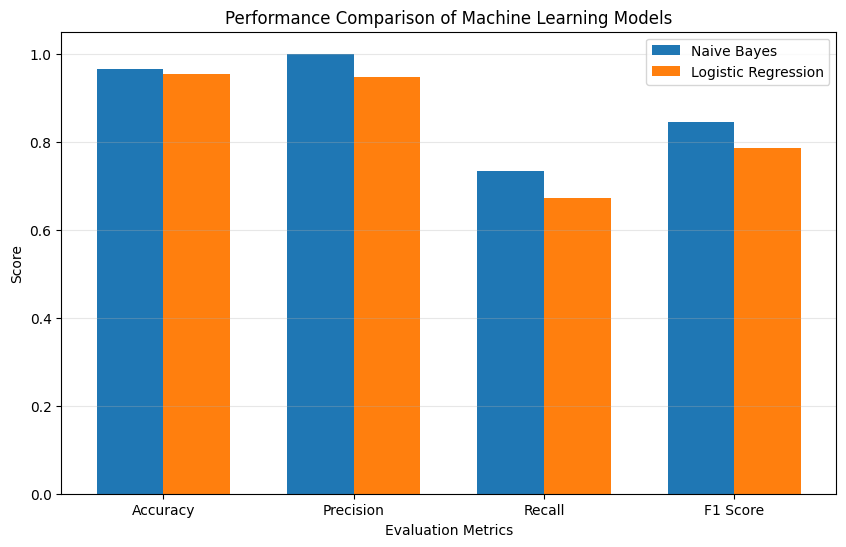

In [40]:
# Visual comparison of model performance

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    results.iloc[0, 1:],
    width,
    label="Naive Bayes"
)

plt.bar(
    x + width/2,
    results.iloc[1, 1:],
    width,
    label="Logistic Regression"
)

plt.xticks(x, metrics)
plt.ylim(0, 1.05)

plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.title("Performance Comparison of Machine Learning Models")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

### Model Evaluation Observation

Both Multinomial Naive Bayes and Logistic Regression models were evaluated using accuracy, precision, recall, and F1-score.

The evaluation results provide an understanding of how effectively each model identifies spam and legitimate messages. The performance comparison helps determine which algorithm is more suitable for this classification task.

Recall and precision are given special consideration because missed spam messages and incorrectly classified legitimate messages can affect the reliability of the spam detection system.

# 7. Confusion Matrix Analysis

A confusion matrix is an evaluation technique used to measure the performance of a classification model. It compares the actual class labels with the predicted class labels.

In this project, confusion matrices are generated for Multinomial Naive Bayes and Logistic Regression to identify correct and incorrect spam and ham predictions.

In [41]:
# Import confusion matrix libraries

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print("Confusion matrix libraries imported successfully!")

Confusion matrix libraries imported successfully!


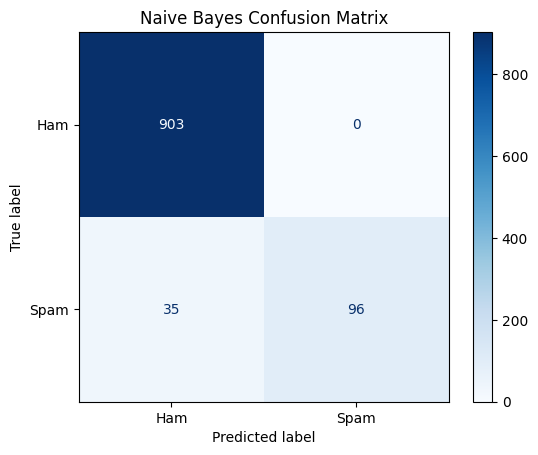

In [42]:
# Generate confusion matrix for Naive Bayes

cm_nb = confusion_matrix(
    y_test,
    nb_predictions,
    labels=["ham", "spam"]
)

# Display confusion matrix

disp_nb = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=["Ham", "Spam"]
)

disp_nb.plot(cmap="Blues", values_format="d")

plt.title("Naive Bayes Confusion Matrix")
plt.show()

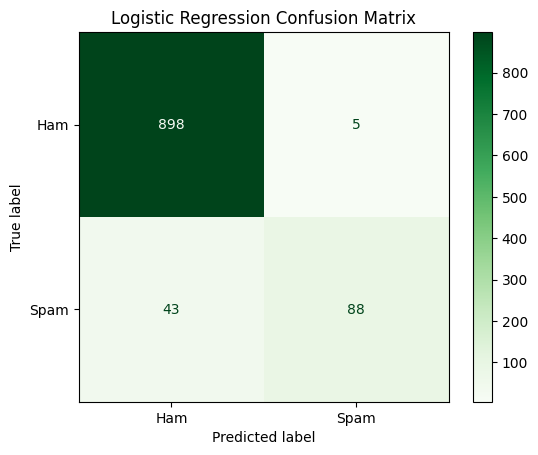

In [43]:
# Generate confusion matrix for Logistic Regression

cm_lr = confusion_matrix(
    y_test,
    lr_predictions,
    labels=["ham", "spam"]
)

# Display confusion matrix

disp_lr = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["Ham", "Spam"]
)

disp_lr.plot(cmap="Greens", values_format="d")

plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [44]:
# Extract confusion matrix values for Naive Bayes

tn_nb, fp_nb, fn_nb, tp_nb = cm_nb.ravel()

print("Naive Bayes Results")

print("True Negative:", tn_nb)
print("False Positive:", fp_nb)
print("False Negative:", fn_nb)
print("True Positive:", tp_nb)

Naive Bayes Results
True Negative: 903
False Positive: 0
False Negative: 35
True Positive: 96


In [45]:
# Extract confusion matrix values for Logistic Regression

tn_lr, fp_lr, fn_lr, tp_lr = cm_lr.ravel()

print("Logistic Regression Results")

print("True Negative:", tn_lr)
print("False Positive:", fp_lr)
print("False Negative:", fn_lr)
print("True Positive:", tp_lr)

Logistic Regression Results
True Negative: 898
False Positive: 5
False Negative: 43
True Positive: 88


In [46]:
# Compare false negatives

print("Spam Detection Comparison")

print("Naive Bayes False Negatives:", fn_nb)

print("Logistic Regression False Negatives:", fn_lr)

Spam Detection Comparison
Naive Bayes False Negatives: 35
Logistic Regression False Negatives: 43


### Confusion Matrix Observation

Confusion matrices were generated for both Multinomial Naive Bayes and Logistic Regression models.

The matrices show the number of correctly and incorrectly classified spam and ham messages. True Positives and True Negatives represent correct predictions, while False Positives and False Negatives represent classification errors.

The false-negative values are particularly important because they indicate spam messages incorrectly classified as legitimate messages.

# 8. Importance of Recall in Spam Detection

Recall is an important evaluation metric in spam detection because it measures the ability of a model to identify actual spam messages correctly.

A high recall score indicates that the model successfully detects most spam messages, reducing the number of spam messages incorrectly classified as legitimate messages.

In spam detection, low recall can allow unwanted or potentially fraudulent messages to reach users' inboxes.

Therefore, recall is particularly important because the main objective of a spam detection system is to identify as many actual spam messages as possible.

However, precision must also be considered to avoid incorrectly classifying legitimate messages as spam.

In [47]:
# Calculate recall manually

nb_recall = tp_nb / (tp_nb + fn_nb)

lr_recall = tp_lr / (tp_lr + fn_lr)

print("Naive Bayes Recall:", round(nb_recall, 4))

print("Logistic Regression Recall:", round(lr_recall, 4))

Naive Bayes Recall: 0.7328
Logistic Regression Recall: 0.6718


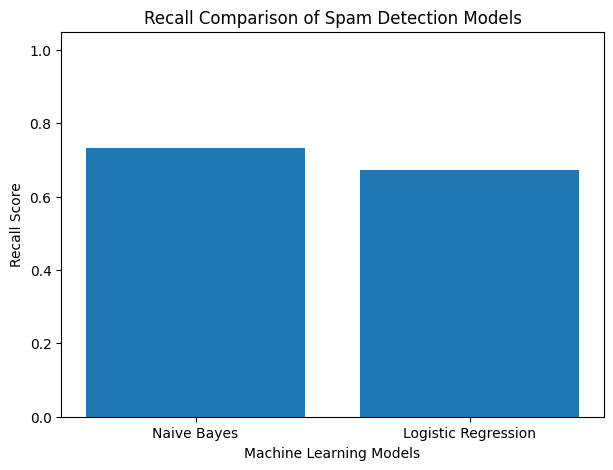

In [48]:
# Visualize recall comparison

models = ["Naive Bayes", "Logistic Regression"]

recall_values = [nb_recall, lr_recall]

plt.figure(figsize=(7, 5))

plt.bar(models, recall_values)

plt.ylim(0, 1.05)

plt.title("Recall Comparison of Spam Detection Models")

plt.xlabel("Machine Learning Models")
plt.ylabel("Recall Score")

plt.show()

### Recall Analysis Observation

Recall measures how effectively a spam detection model identifies actual spam messages.

A higher recall score indicates fewer spam messages are incorrectly classified as legitimate messages. Both models were compared using recall to understand their ability to detect spam.

Recall is particularly important in this project because missed spam messages can reduce the effectiveness of the spam detection system. However, a balance between recall and precision is also necessary.

## 11. Bonus: WordCloud Visualization

WordClouds visually represent frequently occurring words in a text dataset. Words appearing more frequently are displayed larger.

Separate WordClouds are generated for spam and ham messages to compare their common vocabulary.

In [49]:
from wordcloud import WordCloud

In [50]:
!pip install wordcloud

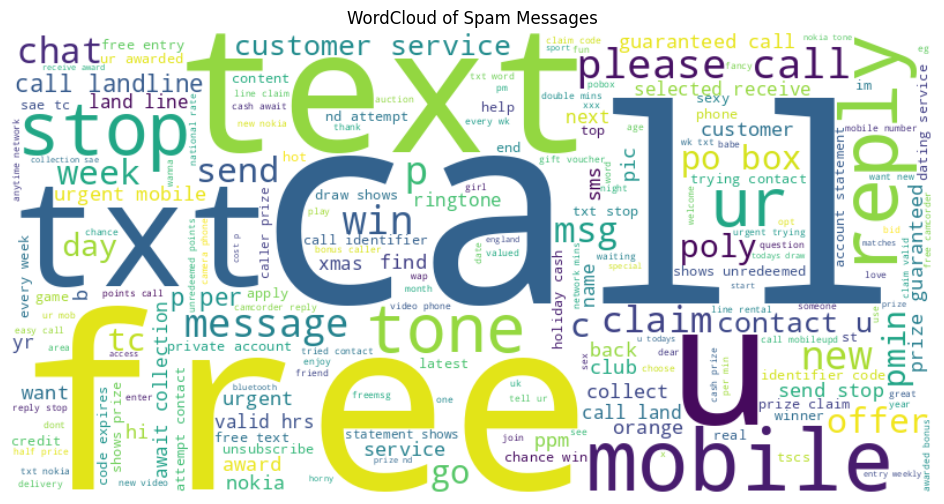

In [51]:
spam_text = " ".join(
    df.loc[df["label"] == "spam", "cleaned_message"]
)

spam_wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(spam_text)

plt.figure(figsize=(12, 6))
plt.imshow(spam_wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("WordCloud of Spam Messages")
plt.show()

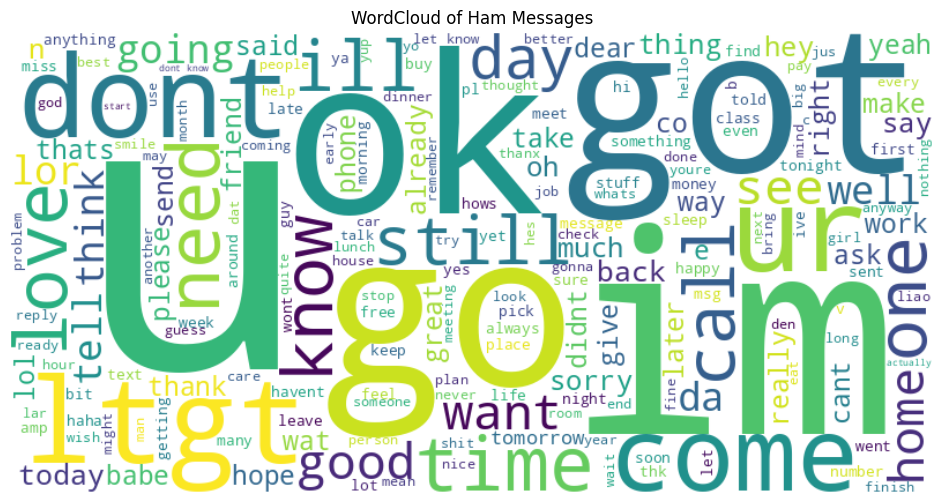

In [52]:
ham_text = " ".join(
    df.loc[df["label"] == "ham", "cleaned_message"]
)

ham_wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(ham_text)

plt.figure(figsize=(12, 6))
plt.imshow(ham_wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("WordCloud of Ham Messages")
plt.show()

### WordCloud Observations

- The spam WordCloud highlights frequently occurring words associated with promotional messages, offers, prizes, and notifications.
- The ham WordCloud highlights words commonly used in normal personal conversations.
- WordCloud visualization helps understand differences in vocabulary between spam and ham messages.

## 12. Testing the Spam Detection Model

The trained models are tested using new sample messages to check whether they can correctly classify messages as spam or ham.

In [53]:
def predict_message(message, model):
    cleaned_message = preprocess_text(message)

    message_vector = tfidf.transform([cleaned_message])

    prediction = model.predict(message_vector)[0]

    return prediction

In [54]:
sample_messages = [
    "Congratulations! You have won a free prize. Claim your reward now!",
    "Hey, are we meeting for lunch today?",
    "URGENT! You have been selected for a cash prize. Call now!",
    "Please send me the assignment notes."
]

for message in sample_messages:
    nb_prediction = predict_message(message, nb_model)
    lr_prediction = predict_message(message, lr_model)

    print("Message:", message)
    print("Naive Bayes Prediction:", nb_prediction)
    print("Logistic Regression Prediction:", lr_prediction)
    print("-" * 70)

Message: Congratulations! You have won a free prize. Claim your reward now!
Naive Bayes Prediction: spam
Logistic Regression Prediction: spam
----------------------------------------------------------------------
Message: Hey, are we meeting for lunch today?
Naive Bayes Prediction: ham
Logistic Regression Prediction: ham
----------------------------------------------------------------------
Message: URGENT! You have been selected for a cash prize. Call now!
Naive Bayes Prediction: spam
Logistic Regression Prediction: spam
----------------------------------------------------------------------
Message: Please send me the assignment notes.
Naive Bayes Prediction: ham
Logistic Regression Prediction: ham
----------------------------------------------------------------------


### Testing Observations

- The models classify new messages into spam or ham categories.
- Promotional and prize-related messages may be identified as spam.
- Normal conversational messages may be classified as ham.
- Testing helps demonstrate how the trained models work on unseen messages.

Predictions are not guaranteed to be correct for every message.

## 13. Conclusion

In this project, a machine learning-based spam detection system was developed using Python and Natural Language Processing techniques.

The SMS Spam Collection dataset was cleaned and preprocessed by converting text to lowercase, removing punctuation, and eliminating stopwords.

TF-IDF vectorization was used to convert text messages into numerical features. Two machine learning algorithms, Multinomial Naive Bayes and Logistic Regression, were trained and evaluated.

The models were compared using accuracy, precision, recall, F1-score, and confusion matrices. WordCloud visualizations were also created to understand frequently occurring words in spam and ham messages.

The project demonstrates how Natural Language Processing and machine learning can be used to classify unwanted messages automatically.